In [15]:
import numpy as np
import matplotlib.pyplot as plt
from src_gypsum import vis

# Usamos LaTeX para los tectos de la figura.
plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",  
    "font.serif": ["Computer Modern Roman"],
})

In [19]:
#
# Cargar los datos desde archivos
# -----
c1 = np.load('nr_analysis/c1_exact.npy')
c2 = np.load('nr_analysis/c2_exact.npy')
c1_fine = np.load('nr_analysis/c1_exact_200.npy')
c2_fine = np.load('nr_analysis/c2_exact_200.npy')
x_fine = np.linspace(0,30,200)

#
# Dimensiones de los datos
# -----
steps = c1.shape[0]
Nx = c2.shape[1]

#
# Dimensiones espacial y temporal
# -----
x = np.array([i - 0.5 for i in range(1, Nx + 1)], dtype=float)
times = np.array([i for i in range(0, steps)])

In [157]:
filename = ["nr_analysis/gypsum_eq_dfc.out", 
            "nr_analysis/gypsum_eq_dfc.outgwf_api_",
            "nr_analysis/gypsum_eq_gwt.outgwf_gwt_api_",
            "nr_analysis/gypsum_eq_exch.outgwf_gwt_exch_api_"]
c_num = []
for i in range(1,41):
    c_num.append(vis.data_recovery(filename[1] + f"{i:02d}"))

In [160]:
print(c_num[0][0])
print(c1[0], len(c1))

[  1.00003   1.00003   1.00004   1.00007   1.00032   1.0025    1.0214
   1.18489   2.5997   14.8426  120.784    42.5277   15.3971    5.99132
   2.73044   1.59994   1.20801   1.07214   1.02503   1.0087    1.00304
   1.00107   1.00039   1.00016   1.00008   1.00005   1.00004   1.00003
   1.00003   1.00003]
[  1.00003294   1.00003294   1.00003294   1.00003294   1.00003294
   1.00003294   1.00003294   1.00003294   1.00003294   1.00003294
 201.00000033   1.00003294   1.00003294   1.00003294   1.00003294
   1.00003294   1.00003294   1.00003294   1.00003294   1.00003294
   1.00003294   1.00003294   1.00003294   1.00003294   1.00003294
   1.00003294   1.00003294   1.00003294   1.00003294   1.00003294] 41


In [163]:
RMSE1 = []
RMSE2 = []
MAPE1 = []
MAPE2 = []

for t in range(1,41):
    RMSE1.append(np.linalg.norm(c1[t] - c_num[t-1][0]) / np.sqrt(len(c_num[t-1][0])))
    RMSE2.append(np.linalg.norm(c2[t] - c_num[t-1][1]) / np.sqrt(len(c_num[t-1][1])))
    MAPE1.append(np.mean(np.abs((c1[t] - c_num[t-1][0]) / c1[t])) * 100)
    MAPE2.append(np.mean(np.abs((c2[t] - c_num[t-1][1]) / c2[t])) * 100)

[np.float64(9.295350655264633), np.float64(5.885998754240557), np.float64(3.9364200381110352), np.float64(2.965942397259651), np.float64(2.433717091002894), np.float64(2.103186594444045), np.float64(1.8766710010612493), np.float64(1.710520123742003), np.float64(1.5827039614269103), np.float64(1.4809173225675054), np.float64(1.3976790982458875), np.float64(1.3281591609857017), np.float64(1.2690998395981268), np.float64(1.218183961527836), np.float64(1.17371834955758), np.float64(1.1344380405166405), np.float64(1.0992767361960134), np.float64(1.0674425046284832), np.float64(1.0381989852317688), np.float64(1.010949221370133), np.float64(0.9852651567625257), np.float64(0.9608097674975455), np.float64(0.9374408756938823), np.float64(0.9151128500433909), np.float64(0.893851574722658), np.float64(0.8737181693356091), np.float64(0.854689414963717), np.float64(0.8366938774413857), np.float64(0.8194884065797421), np.float64(0.8027202169831446), np.float64(0.7859402114753553), np.float64(0.768681

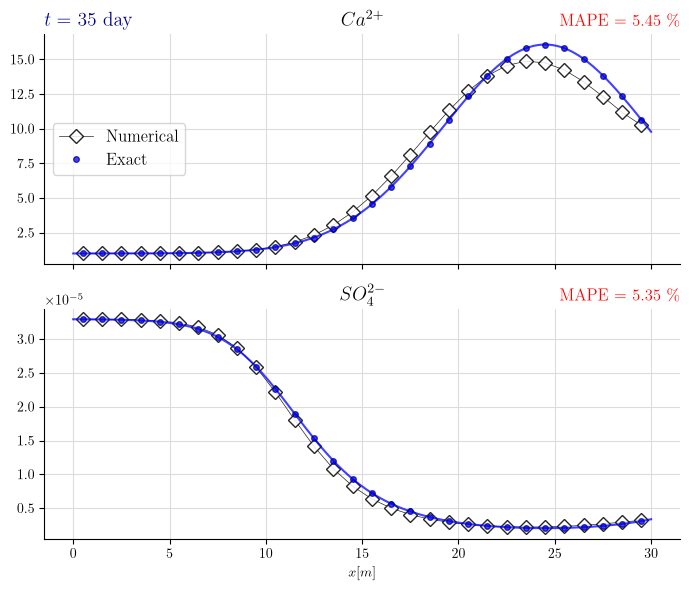

In [263]:
#
# Definir la figura
# -----
fig, ax = plt.subplots(2, 1, sharex=True, figsize=(7,6))

#
# Graficar todos los pasos
# -----
color = "gainsboro"
lw = 0.5
#for t in times[1:]:
#    ax[0].plot(x_fine, c1_fine[t], c = color, lw = lw)
#    ax[1].plot(x_fine, c2_fine[t], c = color, lw = lw)

#
# Graficar el primer paso
# -----
tsel = 35
num_color = "white"
exact_color = "blue"
lw = 1.5

ax[0].plot(x, c_num[tsel-1][0], "D-", c = "k", alpha = 0.85, mec="black", mfc=num_color, 
           markersize=7, lw = 0.5, label = f"Numerical")

ax[1].plot(x, c_num[tsel-1][1], "D-", c = "k", alpha = 0.85, mec="black", mfc=num_color, 
           markersize=7, lw = 0.5, label = f"Numerical")

ax[0].plot(x_fine, c1_fine[tsel], "-", c = exact_color, alpha = 0.75, lw = lw)
ax[0].plot(x, c1[tsel], ".", c = "darkblue", alpha = 0.75, mec="darkblue", mfc="blue", 
           markersize=8, lw = lw, label = f"Exact")

ax[1].plot(x_fine, c2_fine[tsel], "-", c = exact_color, alpha = 0.75, lw = lw)
ax[1].plot(x, c2[tsel], ".", c = "darkblue", alpha = 0.75, mec="darkblue", mfc="blue", 
           markersize=8, lw = lw, label = f"Exact")


#
# Decoración de la gráfica
# -----
ax[0].grid(color=color)
ax[1].grid(color=color)

ax[0].legend(loc='center left', ncol=1, fontsize=12)
#ax[1].legend()

ax[0].spines.right.set_visible(False)
ax[0].spines.top.set_visible(False)

ax[1].spines.right.set_visible(False)
ax[1].spines.top.set_visible(False)

ax[1].set_xlabel("$x [m]$")

ax[0].set_title(f"$t = $ {tsel} day", loc="left", fontsize=14, color="darkblue")
ax[0].set_title("$Ca^{2+}$", loc="center", fontsize=14, color="k")
ax[0].set_title(f"MAPE = {MAPE1[tsel-1]:5.2f} \\%", loc="right", color="r")

ax[1].set_title("$SO_4^{2-}$", loc="center", fontsize=14, color="k")
ax[1].set_title(f"MAPE = {MAPE2[tsel-1]:5.2f} \\%", loc="right", color="r")

#plt.suptitle(f"Species concentration.", x = 0.05, ha="left", fontsize=14)
plt.tight_layout()
plt.savefig(f"gypsum_comp_{tsel:02d}.png", dpi=200)
plt.show()

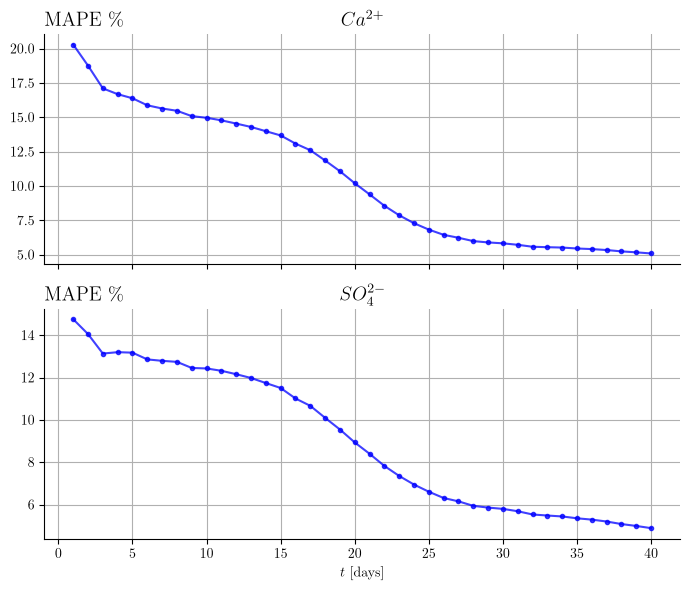

In [264]:
fig, ax = plt.subplots(2, 1, sharex=True, figsize=(7,6))

ax[0].plot(times[1:], MAPE1, ".-", c = exact_color, alpha = 0.75, lw = lw)
ax[1].plot(times[1:], MAPE2, ".-", c = exact_color, alpha = 0.75, lw = lw)

ax[0].spines.right.set_visible(False)
ax[0].spines.top.set_visible(False)

ax[1].spines.right.set_visible(False)
ax[1].spines.top.set_visible(False)

ax[1].set_xlabel("$t$ [days]")
ax[0].grid()
ax[1].grid()

ax[0].set_title("MAPE \\%", loc="left", fontsize=14, color="k")
ax[0].set_title("$Ca^{2+}$", loc="center", fontsize=14, color="k")

ax[1].set_title("MAPE \\%", loc="left", fontsize=14, color="k")
ax[1].set_title("$SO_4^{2-}$", loc="center", fontsize=14, color="k")

plt.tight_layout()
plt.savefig(f"gypsum_mape.png", dpi=200)
plt.show()